# Google Colab + Simple Linear Regression

Goal: predict **apartment price (thousands of PLN)** from **floor area (m²)** with the model

$$y = a \cdot x + b$$

Plan:
1. Load the data (`apartments.csv`).
2. Train `LinearRegression` and plot the fitted line.
3. Predict prices for new areas.
4. Exercises: price per m², its plot, error metrics (MAE / MSE / RMSE / R²), polynomial model with `area_m2²`, saving the plot to PNG.

## 0) Environment check

In [15]:
import sys, platform
print("Python version:", sys.version)
print("Platform:", platform.platform())

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platform: Linux-6.6.122+-x86_64-with-glibc2.39


In [16]:
# In Colab these libraries are already installed. Uncomment only if something is missing:
# !pip install numpy pandas scikit-learn matplotlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 1) Data: `apartments.csv`

Upload `apartments.csv` in Colab (**Files** panel on the left → upload icon), then run the cell below.
If the file is not found, the same data is created directly in code, so the notebook always works.

In [17]:
try:
    df = pd.read_csv("apartments.csv")
    print("Loaded apartments.csv")
except FileNotFoundError:
    print("apartments.csv not found - using the built-in copy of the data")
    df = pd.DataFrame({
        "area_m2": [35, 50, 65, 80, 100, 120],
        "price_thousands_pln": [310, 395, 470, 560, 670, 770],
    })

df

apartments.csv not found - using the built-in copy of the data


,area_m2,price_thousands_pln
0,35,310
1,50,395
2,65,470
3,80,560
4,100,670
5,120,770


In [18]:
df.describe()

,area_m2,price_thousands_pln
count,6.000000,6.000000
mean,75.000000,529.166667
std,31.622777,172.232885
min,35.000000,310.000000
25%,53.750000,413.750000
50%,72.500000,515.000000
75%,95.000000,642.500000
max,120.000000,770.000000


## 2) Simple linear regression

1. Split features **X** (area) and target **y** (price).
2. Fit `LinearRegression`.
3. Inspect the coefficient **a** and intercept **b**.
4. Plot the data and the fitted line.

In [19]:
X = df[["area_m2"]].values          # 2D array: (n_samples, 1 feature)
y = df["price_thousands_pln"].values

model = LinearRegression()
model.fit(X, y)

a = model.coef_[0]
b = model.intercept_
print(f"Coefficient (a): {a:.3f}  -> each extra m² adds about {a:.2f} thousand PLN")
print(f"Intercept   (b): {b:.3f}")
print(f"Model: price = {a:.3f} * area + {b:.3f}")

Coefficient (a): 5.445  -> each extra m² adds about 5.45 thousand PLN
Intercept   (b): 120.792
Model: price = 5.445 * area + 120.792


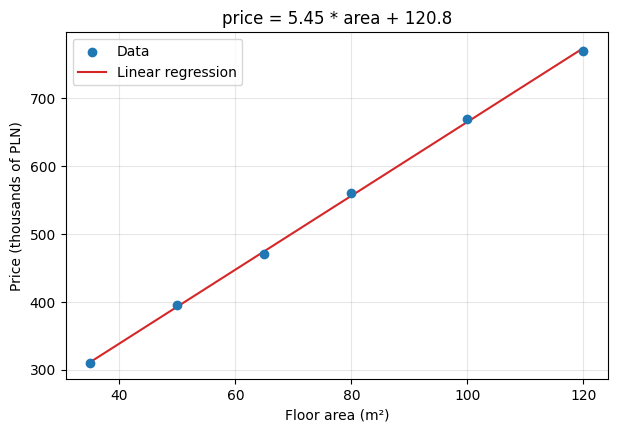

In [20]:
plt.figure(figsize=(7, 4.5))
plt.scatter(X, y, label="Data", zorder=3)
x_line = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
plt.plot(x_line, model.predict(x_line), color="tab:red", label="Linear regression")
plt.xlabel("Floor area (m²)")
plt.ylabel("Price (thousands of PLN)")
plt.title(f"price = {a:.2f} * area + {b:.1f}")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 3) Predictions for new areas

In [21]:
new_areas = np.array([[40], [60], [80], [100]])
predictions = model.predict(new_areas)
for m2, p in zip(new_areas.flatten(), predictions):
    print(f"Predicted price for {m2:>3} m²: {p:7.1f} thousand PLN")

Predicted price for  40 m²:   338.6 thousand PLN
Predicted price for  60 m²:   447.5 thousand PLN
Predicted price for  80 m²:   556.4 thousand PLN
Predicted price for 100 m²:   665.3 thousand PLN


---
# Exercises

### Exercise 1 — price per m²
Add a `price_per_m2` column and see how it changes with area.

In [22]:
df["price_per_m2"] = df["price_thousands_pln"] * 1000 / df["area_m2"]   # PLN per m²
df["price_per_m2"] = df["price_per_m2"].round(0)
df

,area_m2,price_thousands_pln,price_per_m2
0,35,310,8857.0
1,50,395,7900.0
2,65,470,7231.0
3,80,560,7000.0
4,100,670,6700.0
5,120,770,6417.0


**Observation:** the price per m² **decreases** as the area grows (about 8 860 PLN/m² for 35 m² vs about 6 420 PLN/m² for 120 m²).
Larger apartments are cheaper per square metre — this follows from the intercept *b* > 0: a fixed base cost is spread over more m².

### Exercise 2 — plot: area vs price per m²

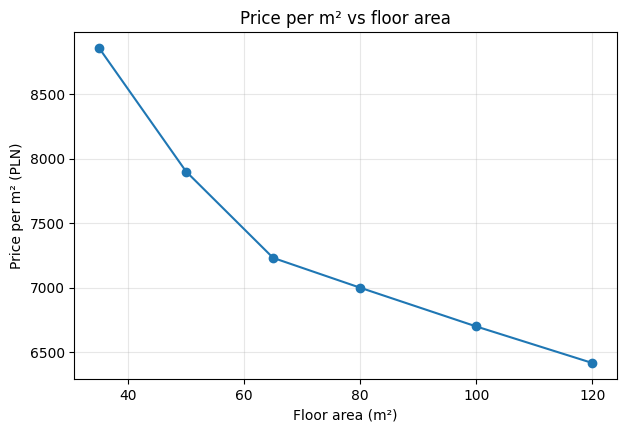

In [23]:
plt.figure(figsize=(7, 4.5))
plt.plot(df["area_m2"], df["price_per_m2"], marker="o")
plt.xlabel("Floor area (m²)")
plt.ylabel("Price per m² (PLN)")
plt.title("Price per m² vs floor area")
plt.grid(alpha=0.3)
plt.show()

### Exercise 3 — model errors: MAE, MSE (+ RMSE, R²)

- **MAE** — mean absolute error (average miss in thousands of PLN),
- **MSE** — mean squared error (penalises large misses more),
- **RMSE** — square root of MSE, in the same units as the price,
- **R²** — share of variance explained (1.0 = perfect fit).

In [24]:
y_pred_lin = model.predict(X)

mae_lin  = mean_absolute_error(y, y_pred_lin)
mse_lin  = mean_squared_error(y, y_pred_lin)
rmse_lin = np.sqrt(mse_lin)
r2_lin   = r2_score(y, y_pred_lin)

print(f"MAE : {mae_lin:.2f} thousand PLN")
print(f"MSE : {mse_lin:.2f}")
print(f"RMSE: {rmse_lin:.2f} thousand PLN")
print(f"R²  : {r2_lin:.4f}")

pd.DataFrame({
    "area_m2": df["area_m2"],
    "actual": y,
    "predicted": y_pred_lin.round(1),
    "error": (y - y_pred_lin).round(1),
})

MAE : 3.42 thousand PLN
MSE : 13.45
RMSE: 3.67 thousand PLN
R²  : 0.9995


,area_m2,actual,predicted,error
0,35,310,311.4,-1.4
1,50,395,393.0,2.0
2,65,470,474.7,-4.7
3,80,560,556.4,3.6
4,100,670,665.3,4.7
5,120,770,774.2,-4.2


### Exercise 4 — second feature `area_m2²` (polynomial model)

We add `area_m2 ** 2` as an extra feature: $y = a_1 x + a_2 x^2 + b$ and compare errors with the linear model.

In [25]:
df["area_m2_sq"] = df["area_m2"] ** 2
X_poly = df[["area_m2", "area_m2_sq"]].values

model_poly = LinearRegression()
model_poly.fit(X_poly, y)
y_pred_poly = model_poly.predict(X_poly)

mae_poly  = mean_absolute_error(y, y_pred_poly)
mse_poly  = mean_squared_error(y, y_pred_poly)
r2_poly   = r2_score(y, y_pred_poly)

print("Polynomial model coefficients:", model_poly.coef_, " intercept:", round(model_poly.intercept_, 3))

comparison = pd.DataFrame({
    "MAE":  [mae_lin, mae_poly],
    "MSE":  [mse_lin, mse_poly],
    "RMSE": [np.sqrt(mse_lin), np.sqrt(mse_poly)],
    "R²":   [r2_lin, r2_poly],
}, index=["Linear", "Polynomial (x + x²)"]).round(4)
comparison

Polynomial model coefficients: [ 5.78477152e+00 -2.18854439e-03]  intercept: 109.443


,MAE,MSE,RMSE,R²
Linear,3.4250,13.4514,3.6676,0.9995
Polynomial (x + x²),2.7691,10.9384,3.3073,0.9996


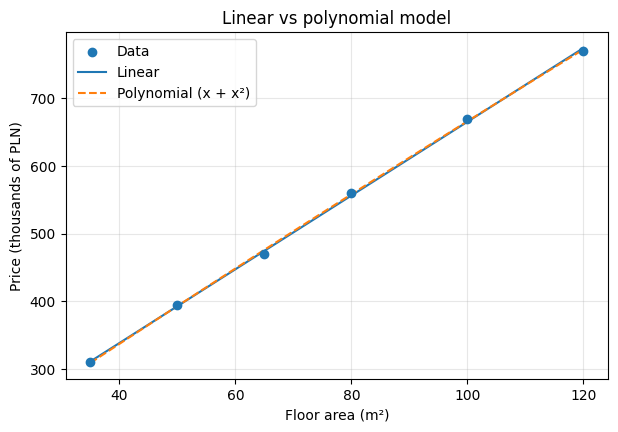

In [26]:
plt.figure(figsize=(7, 4.5))
plt.scatter(X, y, label="Data", zorder=3)
x_line = np.linspace(X.min(), X.max(), 100)
plt.plot(x_line, model.predict(x_line.reshape(-1, 1)), label="Linear")
plt.plot(x_line, model_poly.predict(np.column_stack([x_line, x_line ** 2])),
         linestyle="--", label="Polynomial (x + x²)")
plt.xlabel("Floor area (m²)")
plt.ylabel("Price (thousands of PLN)")
plt.title("Linear vs polynomial model")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Conclusion:** the polynomial model has a lower error on this data (the x² coefficient is slightly negative — price grows a bit slower for large apartments).
However, the data has only 6 points, so the improvement is small and the extra feature can easily overfit; the simple linear model is already very good (R² ≈ 0.999).

### Exercise 5 — save the plot to PNG

`plt.savefig()` must be called **before** `plt.show()`, otherwise the saved image is empty.
After running, the file `regression.png` appears in the **Files** panel — download it and add it to the GitHub repository.

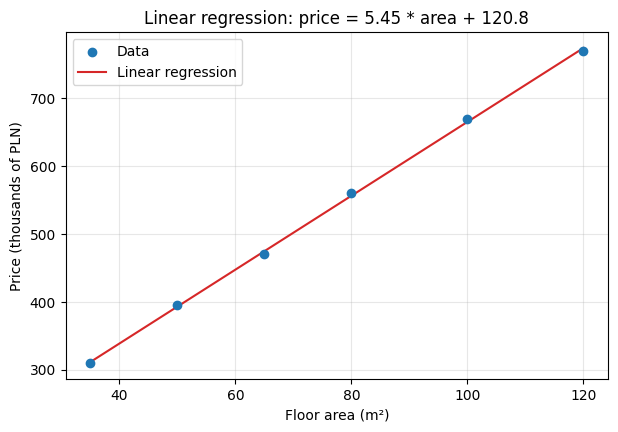

Saved: regression.png


In [27]:
plt.figure(figsize=(7, 4.5))
plt.scatter(X, y, label="Data", zorder=3)
x_line = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
plt.plot(x_line, model.predict(x_line), color="tab:red", label="Linear regression")
plt.xlabel("Floor area (m²)")
plt.ylabel("Price (thousands of PLN)")
plt.title(f"Linear regression: price = {a:.2f} * area + {b:.1f}")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("regression.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: regression.png")

---
## Summary

- Model: price ≈ **a · area + b**, fitted with `LinearRegression`; it fits the data almost perfectly (R² ≈ 0.999).
- Price per m² decreases with area.
- Adding `area_m2²` lowers the error slightly, but with 6 data points the simple linear model is enough.
- The plot is saved as `regression.png`.